In [1]:
!pip install open3d --upgrade --no-cache-dir  # Colab only; locally use requirements.txt

#**Milestone I**

**1. Proper Data Loading**

In [2]:
import numpy as np
import open3d as o3d
import pandas as pd

# Load data
# Place the dataset folder next to this notebook (see README) or change DATA_DIR.
# On Google Colab you can mount Drive instead:
#   from google.colab import drive; drive.mount('/content/drive')
#   DATA_DIR = '/content/drive/MyDrive/Research lab/train_dataset_practical/5'
DATA_DIR = 'data/5'
data_df = pd.read_csv(f'{DATA_DIR}/data.csv', header=0)

print("First few data:")
print(data_df.head())

# Convert to numeric values & remove NaN
data_df = data_df.apply(pd.to_numeric, errors='coerce').dropna()

# Create Open3D point cloud
data_points = data_df.values
data_point_cloud_data = o3d.geometry.PointCloud()
data_point_cloud_data.points = o3d.utility.Vector3dVector(data_points)

print(f"\nData Bounding")
data_points_np = np.asarray(data_point_cloud_data.points)
for i, axis in enumerate("XYZ"):
    print(f"{axis}: [{data_points_np[:, i].min():.3f}, {data_points_np[:, i].max():.3f}]")

print(f"\nData center: {data_points_np.mean(axis=0)}")

First few data:
           X          Y         Z
0 -31.272779   6.340537 -0.192794
1 -28.790613 -32.167488 -2.269696
2 -18.087065   3.713892 -0.151621
3 -10.574847 -12.335940 -0.926267
4  18.515892  -6.721733 -0.209755

Data Bounding
X: [-32.941, 33.150]
Y: [-32.898, 32.985]
Z: [-2.326, 13.048]

Data center: [0.87160812 0.12233863 0.79431417]


**2. Loading Gear Model**

In [3]:
mesh = o3d.io.read_triangle_mesh(f"{DATA_DIR}/5.stl")
print("\n" + "="*20)
print('Given Model (STL)')
print("="*20)
o3d.visualization.draw_plotly([mesh])
model_point_data = mesh.sample_points_uniformly(number_of_points=5000)
model_points = np.asarray(model_point_data.points)

print(f"\nModel bounding")
for i, axis in enumerate(['X', 'Y', 'Z']):
    print(f"{axis}: [{model_points[:, i].min():.3f}, {model_points[:, i].max():.3f}]")
print(f"Model center: {model_points.mean(axis=0)}")

# Visualize
model_point_data.paint_uniform_color([1, 0, 0])
data_point_cloud_data.paint_uniform_color([0.7, 0.7, 0.7])
print("\nVisualizing model (red) and data (gray):")
o3d.visualization.draw_plotly([model_point_data, data_point_cloud_data])


Given Model (STL)


[interactive 3D view removed to keep the notebook small - see images/ in the repo]



Model bounding
X: [-25.213, 27.842]
Y: [-14.294, 13.620]
Z: [0.003, 11.753]
Model center: [ 7.87874244 -1.65822674  4.26362996]

Visualizing model (red) and data (gray):


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


**3. Loading Provided Files**

In [4]:
def point_cloud_data(filename, color):
  data = pd.read_csv(f'{DATA_DIR}/{filename}', header=0)
  points = data.apply(pd.to_numeric, errors='coerce').dropna().values

# Create Open3D point clouds
  point_data = o3d.geometry.PointCloud()
  point_data.points = o3d.utility.Vector3dVector(points)
  point_data.paint_uniform_color(color)
  return point_data

# Visualize
point_data_ok = point_cloud_data('obj_ok.csv', [0, 1, 0])  # Green
point_data_defect = point_cloud_data('obj_defect.csv', [1, 0, 0])  # Red
point_data_background = point_cloud_data('background.csv', [0, 0, 1])  # Blue
print("\nVisualizing provided data (Green=OK, Red=Defect, Blue=Background):")
o3d.visualization.draw_plotly([point_data_ok, point_data_defect, point_data_background])


Visualizing provided data (Green=OK, Red=Defect, Blue=Background):


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


**4. Comparing Model with Provided Data**

In [5]:
# Get raw points from the Step 3
points_ok = np.asarray(point_data_ok.points)
points_defect = np.asarray(point_data_defect.points)

# Combine them into "Scanned Gear"
scan_points = np.vstack([points_ok, points_defect])
point_data_scan = o3d.geometry.PointCloud()
point_data_scan.points = o3d.utility.Vector3dVector(scan_points)
point_data_scan.paint_uniform_color([1, 0.5, 0])  # Orange

# Scale Check (Max - Min) & visualize
scan_size = scan_points.max(axis=0) - scan_points.min(axis=0)
model_points = np.asarray(model_point_data.points)
model_size = model_points.max(axis=0) - model_points.min(axis=0)

print(f"Scan Dimensions:  {scan_size}")
print(f"Model Dimensions: {model_size}")
print(f"Scale Ratio:      {scan_size / model_size}")

o3d.visualization.draw_plotly([model_point_data, point_data_scan])

Scan Dimensions:  [53.12262154 28.48588753 13.17005974]
Model Dimensions: [53.05527655 27.91461092 11.7503907 ]
Scale Ratio:      [1.00126934 1.02046515 1.12081888]


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


**5. Simple Registration**

In [6]:
import copy
# Calculate Centers and Scale
scan_center = point_data_scan.get_center()
model_center = model_point_data.get_center()

# Calculate scale (Scan Size / Model Size)
scan_size = point_data_scan.get_max_bound() - point_data_scan.get_min_bound()
model_size = model_point_data.get_max_bound() - model_point_data.get_min_bound()
scale_factor = np.mean(scan_size / model_size)

print(f"Aligning Scale Factor: {scale_factor:.4f}")

# Align Model to Scan (Translate & Scale)
# Reset model, then move to scan center
model_aligned = copy.deepcopy(model_point_data) # Make a copy
model_aligned.translate(scan_center, relative=False)
model_aligned.scale(scale_factor, center=scan_center)
model_aligned.paint_uniform_color([1, 0, 0]) # Red

# Check Alignment (Using Open3D Native Tools) & Visualize
distance = point_data_scan.compute_point_cloud_distance(model_aligned)
distance = np.asarray(distance)

print(f"Alignment Stats:")
print(f"  Avg Distance: {np.mean(distance):.4f}")
print(f"  Max Distance: {np.max(distance):.4f}")

o3d.visualization.draw_plotly([model_aligned, point_data_scan])

Aligning Scale Factor: 1.0475
Alignment Stats:
  Avg Distance: 4.3034
  Max Distance: 10.3008


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


**6. Finding Gear in Full Scene**

In [7]:
# Align the Model to 'point_data_scan' (from Step 4)
icp_sol = o3d.pipelines.registration.registration_icp(
    model_aligned, point_data_scan, 2.0, np.eye(4),
    o3d.pipelines.registration.TransformationEstimationPointToPoint(),
    o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration=2000))
model_aligned.transform(icp_sol.transformation)

# Find Gear (Step 1 Data)
scene_dists = data_point_cloud_data.compute_point_cloud_distance(model_aligned)
scene_dists = np.asarray(scene_dists)

# Filter
ind = np.where(scene_dists < 2.0)[0]
found_gear = data_point_cloud_data.select_by_index(ind)
found_background = data_point_cloud_data.select_by_index(ind, invert=True)

# Visualize
found_gear.paint_uniform_color([0, 1, 0])       # Green (Found Gear)
found_background.paint_uniform_color([0.5, 0.5, 0.5]) # Gray (Background)

print(f"Total Scene Points: {len(data_point_cloud_data.points)}")
print(f"Gear Points Found:  {len(found_gear.points)}")

print("Visualizing: Green (Found Gear) + Gray (Background)")
o3d.visualization.draw_plotly([found_gear, found_background])

Total Scene Points: 31008
Gear Points Found:  6427
Visualizing: Green (Found Gear) + Gray (Background)


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


**7. Comparing with Provided Classification**

In [8]:
from scipy.spatial import cKDTree
from sklearn.metrics import confusion_matrix, accuracy_score

icp_sol = o3d.pipelines.registration.registration_icp(
    model_aligned, point_data_scan, 2.0, np.eye(4),        # align the model to point_data_scan (at 4)
    o3d.pipelines.registration.TransformationEstimationPointToPoint(),
    o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration=2000))
model_aligned.transform(icp_sol.transformation)

# Prepare answer key
all_provided = np.vstack([
    np.asarray(point_data_ok.points),  # Label 1 = Gear (OK )
    np.asarray(point_data_defect.points),  # label 1 = Gear (defect)
    np.asarray(point_data_background.points)]) # label 0 = background
true_labels = np.concatenate([
    np.ones(len(point_data_ok.points) + len(point_data_defect.points)),
    np.zeros(len(point_data_background.points))])

# Matching
scene_points = np.asarray(data_point_cloud_data.points)
scene_tree = cKDTree(scene_points)
distance_to_scene, scene_indices = scene_tree.query(all_provided, workers=-1)

# Filtering
valid_mask = distance_to_scene < 0.1
matched_indices = scene_indices[valid_mask]
matched_true_labels = true_labels[valid_mask]

# Predict & Score
# check distances against the ROTATED model_aligned
model_tree = cKDTree(np.asarray(model_aligned.points))
distance_to_model, _ = model_tree.query(scene_points[matched_indices], workers=-1)
predicted_labels = (distance_to_model < 2.0).astype(int)

accuracy = accuracy_score(matched_true_labels, predicted_labels)
confusion_matrix = confusion_matrix(matched_true_labels, predicted_labels)
print(f"Accuracy: {accuracy*100:.2f}%")
print(f"Confusion Matrix (0=Background, 1=Gear):\n{confusion_matrix}")

# Visualize (Green=Correct Gear, Blue=Correct Background, Purple=Error)
point_data_vizualize = o3d.geometry.PointCloud()
point_data_vizualize.points = o3d.utility.Vector3dVector(scene_points[matched_indices])

colors = np.zeros((len(matched_indices), 3))
colors[:] = [0, 0, 1] # Default color: Blue (Background)

correct_gear = (matched_true_labels == 1) & (predicted_labels == 1)
colors[correct_gear] = [0, 1, 0]  # Green: Where Truth=1 AND Prediction=1

errors = matched_true_labels != predicted_labels
colors[errors] = [1, 0, 1]  # Purple: Mismatches

point_data_vizualize.colors = o3d.utility.Vector3dVector(colors)
o3d.visualization.draw_plotly([point_data_vizualize])

Accuracy: 82.03%
Confusion Matrix (0=Background, 1=Gear):
[[24505  5495]
 [   76   932]]


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


#**Milestone II**

**1. Refining Foreground-Background Segmentation**


Analyzing distance distribution...


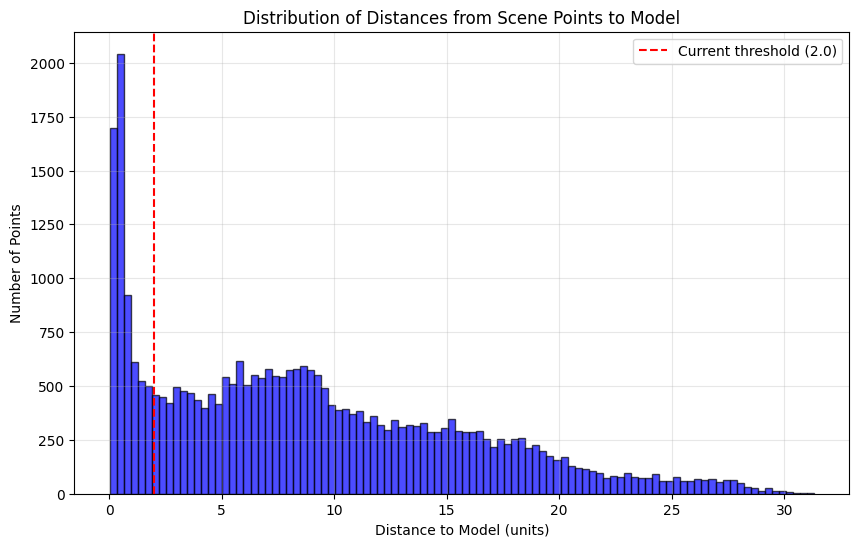

Percentile 50%: threshold=7.740, gear points=15504 (50.0%)
Percentile 75%: threshold=13.455, gear points=23256 (75.0%)
Percentile 90%: threshold=18.716, gear points=27907 (90.0%)
Percentile 95%: threshold=21.900, gear points=29457 (95.0%)
Percentile 97%: threshold=24.296, gear points=30077 (97.0%)
Percentile 99%: threshold=27.335, gear points=30697 (99.0%)

Target gear count (from Training Data): 1008
Optimal threshold found: 0.252
Expected gear points: 1008

=== Optimal Segmentation Results ===
Threshold: 0.2517367665780265
Gear points: 1008 (3.3%)
Background points: 30000

Visualizing optimal segmentation (Green=Gear, Gray=Background):


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


In [9]:
import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
from scipy.spatial import cKDTree

# Setup Data
scene_points_np = np.asarray(data_point_cloud_data.points)
model_points_aligned = np.asarray(model_aligned.points)

print("\nAnalyzing distance distribution...")

# Get distances from all scene points to the aligned model
model_tree = cKDTree(model_points_aligned)
distances_all, _ = model_tree.query(scene_points_np, workers=-1)

# Plot distance histogram
plt.figure(figsize=(10, 6))
plt.hist(distances_all, bins=100, alpha=0.7, color='blue', edgecolor='black')
plt.axvline(x=2.0, color='red', linestyle='--', label=f'Current threshold (2.0)')
plt.xlabel('Distance to Model (units)')
plt.ylabel('Number of Points')
plt.title('Distribution of Distances from Scene Points to Model')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Analyze percentiles
percentiles = [50, 75, 90, 95, 97, 99]
for p in percentiles:
    threshold_val = np.percentile(distances_all, p)
    gear_count = np.sum(distances_all < threshold_val)
    print(f"Percentile {p}%: threshold={threshold_val:.3f}, gear points={gear_count} ({gear_count/len(scene_points_np)*100:.1f}%)")

# Find Optimal Threshold
target_gear_count = len(point_data_ok.points) + len(point_data_defect.points)
print(f"\nTarget gear count (from Training Data): {target_gear_count}")

sorted_dists = np.sort(distances_all)

idx = min(target_gear_count, len(sorted_dists) - 1) # Safety index to avoid out of bounds
best_threshold = sorted_dists[idx]

print(f"Optimal threshold found: {best_threshold:.3f}")
print(f"Expected gear points: {np.sum(distances_all < best_threshold)}")

# optimal threshold
optimal_threshold = best_threshold
gear_mask_optimal = distances_all < optimal_threshold
gear_points_optimal = scene_points_np[gear_mask_optimal]
background_points_optimal = scene_points_np[~gear_mask_optimal]

print(f"\n=== Optimal Segmentation Results ===")
print(f"Threshold: {optimal_threshold}")
print(f"Gear points: {len(gear_points_optimal)} ({len(gear_points_optimal)/len(scene_points_np)*100:.1f}%)")
print(f"Background points: {len(background_points_optimal)}")

# visualization
point_cloud_data_gear_optimal = o3d.geometry.PointCloud()
point_cloud_data_gear_optimal.points = o3d.utility.Vector3dVector(gear_points_optimal)
point_cloud_data_gear_optimal.paint_uniform_color([0, 1, 0])  # Green

point_cloud_data_background_optimal = o3d.geometry.PointCloud()
point_cloud_data_background_optimal.points = o3d.utility.Vector3dVector(background_points_optimal)
point_cloud_data_background_optimal.paint_uniform_color([0.5, 0.5, 0.5])  # Gray

print("\nVisualizing optimal segmentation (Green=Gear, Gray=Background):")
o3d.visualization.draw_plotly([point_cloud_data_gear_optimal, point_cloud_data_background_optimal])

**2. Advanced Segmentation Using DBSCAN**

In [10]:
from sklearn.cluster import DBSCAN

# Isolate points near the gear for better clustering
gear_region_mask = distances_all < 5.0
gear_region_points = scene_points_np[gear_region_mask]

print(f"Points in gear region (distance < 5.0): {len(gear_region_points)}")

# DBSCAN
dbscan = DBSCAN(eps=1.0, min_samples=10, n_jobs=-1)
labels = dbscan.fit_predict(gear_region_points)

# Find the largest cluster
unique_labels, counts = np.unique(labels, return_counts=True)
print(f"\nDBSCAN clusters found: {len(unique_labels)}")

for label, count in zip(unique_labels, counts):
    if label == -1:  # Label -1 is noise
        print(f"  Noise points: {count}")
    else:
        print(f"  Cluster {label}: {count} points")

# Select the largest cluster as the Gear
gear_points_dbscan = np.array([])
background_points_dbscan = np.array([])

if len(unique_labels) > 1:
    # Filter noise
    valid_mask = unique_labels != -1
    if np.any(valid_mask):
        valid_labels = unique_labels[valid_mask]
        valid_counts = counts[valid_mask]
        largest_cluster_label = valid_labels[np.argmax(valid_counts)]

        gear_mask_dbscan = labels == largest_cluster_label
        gear_points_dbscan = gear_region_points[gear_mask_dbscan]

        # Remaining points in the region are background
        background_region_points = gear_region_points[~gear_mask_dbscan]

        # Combine with points outside the region
        background_far_points = scene_points_np[~gear_region_mask]
        background_points_dbscan = np.vstack([background_region_points, background_far_points])

        print(f"\nDBSCAN Segmentation Results:")
        print(f"  Gear points: {len(gear_points_dbscan)}")
        print(f"  Background points: {len(background_points_dbscan)}")

        # visualization
        point_cloud_data_gear_dbscan = o3d.geometry.PointCloud()
        point_cloud_data_gear_dbscan.points = o3d.utility.Vector3dVector(gear_points_dbscan)
        point_cloud_data_gear_dbscan.paint_uniform_color([0, 1, 0])  # Green

        point_cloud_data_background_dbscan = o3d.geometry.PointCloud()
        point_cloud_data_background_dbscan.points = o3d.utility.Vector3dVector(background_points_dbscan)
        point_cloud_data_background_dbscan.paint_uniform_color([0.5, 0.5, 0.5])  # Gray

        print("\nVisualizing DBSCAN segmentation:")
        o3d.visualization.draw_plotly([point_cloud_data_gear_dbscan, point_cloud_data_background_dbscan])
    else:
        print("Only noise found in region.")
else:
    print("No clusters found.")

Points in gear region (distance < 5.0): 10724

DBSCAN clusters found: 4
  Noise points: 292
  Cluster 0: 10278 points
  Cluster 1: 118 points
  Cluster 2: 36 points

DBSCAN Segmentation Results:
  Gear points: 10278
  Background points: 20730

Visualizing DBSCAN segmentation:


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


**3. Statistical Analysis of Segmentation**

In [11]:
def calculate_segmentation_metrics(predicted_gear_points, true_gear_points):
    if len(predicted_gear_points) == 0:
        return {'precision': 0, 'recall': 0, 'f1_score': 0}

    # Create KDTree for true gear points
    true_gear_tree = cKDTree(true_gear_points)
    distances_to_true_gear, _ = true_gear_tree.query(predicted_gear_points, workers=-1)  # For each predicted gear point, check if it's close to a true gear point

    # True positives: predicted points close to true points
    tp_mask = distances_to_true_gear < 0.1
    true_positives = np.sum(tp_mask)

    # False positives
    false_positives = len(predicted_gear_points) - true_positives

    # False negatives
    predicted_tree = cKDTree(predicted_gear_points)
    distances_to_predicted, _ = predicted_tree.query(true_gear_points, workers=-1)
    false_negatives = np.sum(distances_to_predicted >= 0.1)

    # metrics
    precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0
    recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return {
        'true_positives': true_positives,
        'false_positives': false_positives,
        'false_negatives': false_negatives,
        'precision': precision,
        'recall': recall,
        'f1_score': f1_score
    }

# Calculate metrics using combined training data as ground truth
true_gear_combined = np.vstack([np.asarray(point_data_ok.points), np.asarray(point_data_defect.points)])

print("Calculating metrics for distance-based segmentation:")
metrics_distance = calculate_segmentation_metrics(gear_points_optimal, true_gear_combined)
for key, value in metrics_distance.items():
    print(f"  {key}: {value:.4f}" if isinstance(value, float) else f"  {key}: {value}")

print("\nCalculating metrics for DBSCAN segmentation:")
if len(gear_points_dbscan) > 0:
    metrics_dbscan = calculate_segmentation_metrics(gear_points_dbscan, true_gear_combined)
    for key, value in metrics_dbscan.items():
        print(f"  {key}: {value:.4f}" if isinstance(value, float) else f"  {key}: {value}")

Calculating metrics for distance-based segmentation:
  true_positives: 90
  false_positives: 918
  false_negatives: 922
  precision: 0.0893
  recall: 0.0889
  f1_score: 0.0891

Calculating metrics for DBSCAN segmentation:
  true_positives: 763
  false_positives: 9515
  false_negatives: 290
  precision: 0.0742
  recall: 0.7246
  f1_score: 0.1347


**4. Final Segmentation Pipeline**

In [12]:
def segment_foreground_background(model_point_cloud_data, scene_points, method='distance', threshold=1.7):
    model_points = np.asarray(model_point_cloud_data.points)
    model_tree = cKDTree(model_points)
    distances, _ = model_tree.query(scene_points, workers=-1)

    if method == 'distance':
        # Simple distance-based segmentation
        gear_mask = distances < threshold
        gear_points = scene_points[gear_mask]
        background_points = scene_points[~gear_mask]

    elif method == 'dbscan':
        # DBSCAN-based segmentation
        gear_region_mask = distances < 5.0
        gear_region_points = scene_points[gear_region_mask]
        dbscan = DBSCAN(eps=1.0, min_samples=10, n_jobs=-1)
        labels = dbscan.fit_predict(gear_region_points)

        # Find largest cluster (excluding noise)
        unique_labels, counts = np.unique(labels, return_counts=True)

        valid_mask = unique_labels != -1
        if np.any(valid_mask):
            valid_labels = unique_labels[valid_mask]
            valid_counts = counts[valid_mask]
            largest_cluster_label = valid_labels[np.argmax(valid_counts)]

            gear_mask_dbscan = labels == largest_cluster_label
            gear_points = gear_region_points[gear_mask_dbscan]

            # Combine all background points
            background_region_points = gear_region_points[~gear_mask_dbscan]
            background_far_points = scene_points[~gear_region_mask]
            background_points = np.vstack([background_region_points, background_far_points])
        else:
            # Fallback to distance-based
            print("DBSCAN failed, falling back to distance threshold")
            gear_mask = distances < threshold
            gear_points = scene_points[gear_mask]
            background_points = scene_points[~gear_mask]

    else:
        raise ValueError("Method must be 'distance' or 'dbscan'")

    return gear_points, background_points

# Test the pipeline
print("Testing segmentation pipeline...")
gear_final, background_final = segment_foreground_background(
    model_aligned, scene_points_np, method='distance', threshold=optimal_threshold
)

print(f"\nFinal Segmentation Results:")
print(f"Gear points: {len(gear_final)}")
print(f"Background points: {len(background_final)}")

# Save final segmentation
np.savetxt('segmentation_gear_final.csv', gear_final, delimiter=',')
np.savetxt('segmentation_background_final.csv', background_final, delimiter=',')

print("\nFiles saved: segmentation_gear_final.csv, segmentation_background_final.csv")

# Visualization
point_cloud_data_gear_final = o3d.geometry.PointCloud()
point_cloud_data_gear_final.points = o3d.utility.Vector3dVector(gear_final)
point_cloud_data_gear_final.paint_uniform_color([0, 1, 0])  # Green

point_cloud_data_background_final = o3d.geometry.PointCloud()
point_cloud_data_background_final.points = o3d.utility.Vector3dVector(background_final)
point_cloud_data_background_final.paint_uniform_color([0.3, 0.3, 0.3])  # Dark gray

print("\nFinal segmentation visualization:")
o3d.visualization.draw_plotly([point_cloud_data_gear_final, point_cloud_data_background_final])
final_gear = point_cloud_data_gear_final

Testing segmentation pipeline...

Final Segmentation Results:
Gear points: 1008
Background points: 30000

Files saved: segmentation_gear_final.csv, segmentation_background_final.csv

Final segmentation visualization:


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


#**Milestone III**

**1. Feature Extraction**

In [13]:
import numpy as np
import open3d as o3d
from scipy.spatial import cKDTree
from sklearn.neighbors import KDTree

def extract_features_for_anomaly_detection(points, radius=2.0):
    print(f"Extracting features for {len(points)} points.")

    # Using KDTree for robust neighbor search
    tree = KDTree(points)
    features = []

    for i in range(len(points)):
        # Find neighbors within radius
        indices = tree.query_radius(points[i:i+1], r=radius)[0]

        if len(indices) < 5:  # Not enough neighbors
            features.append([0, 0, 0, 0, 0, 0, 0])
            continue

        local_points = points[indices] # Get local neighborhood

        # Density
        density = len(indices)

        # Distance Variance
        distances = np.linalg.norm(local_points - points[i], axis=1)
        distance_variance = np.var(distances)

        # PCA / Eigenvalues
        centered = local_points - np.mean(local_points, axis=0)
        cov_matrix = np.cov(centered.T)
        eigenvalues = np.linalg.eigvalsh(cov_matrix)
        eigenvalues = np.sort(eigenvalues)[::-1]

        if eigenvalues[0] > 0:
            sum_evals = np.sum(eigenvalues) + 1e-10
            surface_variation = eigenvalues[2] / sum_evals
            linearity = (eigenvalues[0] - eigenvalues[1]) / eigenvalues[0]
            planarity = (eigenvalues[1] - eigenvalues[2]) / eigenvalues[0]
            sphericity = eigenvalues[2] / eigenvalues[0]
        else:
            surface_variation = linearity = planarity = sphericity = 0

        features.append([
            density, distance_variance, surface_variation,
            linearity, planarity, sphericity, len(indices)
        ])

    return np.array(features)

# Feature Extraction
print("\n1. Processing Training Data.")
ok_features = extract_features_for_anomaly_detection(np.asarray(point_data_ok.points), radius=1.5)
defect_features = extract_features_for_anomaly_detection(np.asarray(point_data_defect.points), radius=1.5)

print("\n2. Processing Gear Data.")
gear_features = extract_features_for_anomaly_detection(np.asarray(final_gear.points), radius=1.5)

print(f"\nFeature extraction complete.")
print(f"Gear features shape: {gear_features.shape}")


1. Processing Training Data.
Extracting features for 884 points.
Extracting features for 124 points.

2. Processing Gear Data.
Extracting features for 1008 points.

Feature extraction complete.
Gear features shape: (1008, 7)


**2. Model Calibration**

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

# Training Data
print("\nPreparing training data...")
X_train = np.vstack([ok_features, defect_features])
y_train = np.concatenate([np.zeros(len(ok_features)), np.ones(len(defect_features))])

# Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train Random Forest
print("Training Random Forest Classifier.")
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
rf_classifier.fit(X_train_scaled, y_train)

# Training Performance
train_predictions = rf_classifier.predict(X_train_scaled)
print("\nTraining Results:")
print(classification_report(y_train, train_predictions, target_names=['OK', 'Defect']))

# Predict on New Gear Data
print("\nPredicting anomalies on gear points.")
gear_features_scaled = scaler.transform(gear_features)
gear_predictions = rf_classifier.predict(gear_features_scaled)
gear_probabilities = rf_classifier.predict_proba(gear_features_scaled)[:, 1]

print(f"\nPrediction Results:")
print(f"  OK points: {np.sum(gear_predictions == 0)}")
print(f"  Defect points: {np.sum(gear_predictions == 1)}")


Preparing training data...
Training Random Forest Classifier.

Training Results:
              precision    recall  f1-score   support

          OK       1.00      0.98      0.99       884
      Defect       0.86      1.00      0.93       124

    accuracy                           0.98      1008
   macro avg       0.93      0.99      0.96      1008
weighted avg       0.98      0.98      0.98      1008


Predicting anomalies on gear points.

Prediction Results:
  OK points: 1008
  Defect points: 0


**3. Hybrid Detection**

In [15]:
# Geometric Deviation Analysis
print("Performing geometric deviation analysis.")
gear_points_np = np.asarray(final_gear.points)
model_points = np.asarray(model_aligned.points)
model_tree = KDTree(model_points)

# Calculate distances
distances, _ = model_tree.query(gear_points_np)

# Define Threshold
mean_dist = np.mean(distances)
std_dist = np.std(distances)
geo_threshold = mean_dist + (3.0 * std_dist)
geometric_anomalies = (distances > geo_threshold).flatten()

print(f"  Geometric Threshold: {geo_threshold:.4f}")
print(f"  Geometric Anomalies: {np.sum(geometric_anomalies)}")

# Combine (ML Prediction OR Geometric Anomaly)
combined_anomalies = (gear_predictions == 1) | geometric_anomalies

# Separating points for next steps
detected_defects = gear_points_np[combined_anomalies]
detected_ok = gear_points_np[~combined_anomalies]

print(f"\nFinal Combined Detection:")
print(f"  Total Anomalies: {len(detected_defects)}")


Performing geometric deviation analysis.
  Geometric Threshold: 0.3391
  Geometric Anomalies: 0

Final Combined Detection:
  Total Anomalies: 0


**4. Clustering**



In [16]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

# Run DBSCAN on detected defects
if len(detected_defects) > 0:
    print("Clustering detected defects.")
    dbscan = DBSCAN(eps=1.5, min_samples=10)
    cluster_labels = dbscan.fit_predict(detected_defects)

    # Analyze Clusters
    unique_labels = set(cluster_labels)
    if -1 in unique_labels:
        unique_labels.remove(-1)    # Remove noise (-1)

    n_clusters = len(unique_labels)
    print(f"  Number of distinct defect clusters: {n_clusters}")
    print(f"  Noise points removed: {np.sum(cluster_labels == -1)}")

    # Prepare Cluster Visuals
    colors = plt.cm.jet(np.linspace(0, 1, len(unique_labels)))
    cluster_point_cloud_data = []

    for i, label in enumerate(unique_labels):
        cluster_mask = cluster_labels == label
        cluster_points = detected_defects[cluster_mask]

        point_cloud_data_cluster = o3d.geometry.PointCloud()
        point_cloud_data_cluster.points = o3d.utility.Vector3dVector(cluster_points)
        point_cloud_data_cluster.paint_uniform_color(colors[i][:3])
        cluster_point_cloud_data.append(point_cloud_data_cluster)
else:
    print("No defects to cluster.")
    cluster_point_cloud_data = []

# Context cloud (Safe points in Gray)
point_cloud_data_context = o3d.geometry.PointCloud()
point_cloud_data_context.points = o3d.utility.Vector3dVector(detected_ok)
point_cloud_data_context.paint_uniform_color([0.8, 0.8, 0.8])

No defects to cluster.


PointCloud with 1008 points.

**5. validation & visualization**

In [17]:
# Create Point Clouds
point_cloud_data_pred = o3d.geometry.PointCloud()
point_cloud_data_pred.points = o3d.utility.Vector3dVector(detected_defects)
point_cloud_data_pred.paint_uniform_color([1, 0, 0])  # Red (Prediction)

point_cloud_data_truth = o3d.geometry.PointCloud()
point_cloud_data_truth.points = o3d.utility.Vector3dVector(np.asarray(point_data_defect.points))
point_cloud_data_truth.paint_uniform_color([0, 0, 1]) # Blue (Truth)

# Evaluation Function
def evaluate_detection(prediction_point_cloud_data, truth_point_cloud_data):
    if len(prediction_point_cloud_data.points) == 0:
        return 0, 0, 0

    # Move Truth to match Prediction location
    center_pred = prediction_point_cloud_data.get_center()
    center_truth = truth_point_cloud_data.get_center()
    truth_point_cloud_data.translate(center_pred - center_truth)

    # Fine tune alignment
    icp = o3d.pipelines.registration.registration_icp(
        truth_point_cloud_data, prediction_point_cloud_data, 5.0, np.eye(4),
        o3d.pipelines.registration.TransformationEstimationPointToPoint())
    truth_point_cloud_data.transform(icp.transformation)

    # Calculate Metrics
    pred_points = np.asarray(prediction_point_cloud_data.points)
    truth_points = np.asarray(truth_point_cloud_data.points)

    # Precision
    truth_tree = cKDTree(truth_points)
    dists_to_true, _ = truth_tree.query(pred_points, workers=-1)
    true_positives = np.sum(dists_to_true < 2.0) # 2.0 tolerance
    precision = true_positives / len(pred_points)

    # Recall
    pred_tree = cKDTree(pred_points)
    dists_to_pred, _ = pred_tree.query(truth_points, workers=-1)
    found_real = np.sum(dists_to_pred < 2.0)
    recall = found_real / len(truth_points)

    # F1
    f1 = 2 * (precision * recall) / (precision + recall + 1e-10)

    return precision, recall, f1

# Run Evaluation
try:
    prec, rec, f1 = evaluate_detection(point_cloud_data_pred, point_cloud_data_truth)
    print(f"\nFinal Performance Metrics:")
    print(f"  Precision: {prec*100:.2f}%")
    print(f"  Recall:    {rec*100:.2f}%")
    print(f"  F1-Score:  {f1*100:.2f}%")
except Exception as e:
    print(f"Validation skipped (Training data missing or empty): {e}")

# Save Results
np.savetxt('milestone3_defects.csv', detected_defects, delimiter=',')
print("\nSaved detected defects to 'milestone3_defects.csv'")

# Visualization
# Image 1: Basic
point_cloud_data_safe = o3d.geometry.PointCloud()
point_cloud_data_safe.points = o3d.utility.Vector3dVector(detected_ok)
point_cloud_data_safe.paint_uniform_color([0, 1, 0]) # Green
print("\nImage 1: Basic Detection (Green=Safe, Red=Defect)")
o3d.visualization.draw_plotly([point_cloud_data_safe, point_cloud_data_pred])

# Image 2: Clusters
print("Image 2: Defect Clusters")
if len(cluster_point_cloud_data) > 0:
    o3d.visualization.draw_plotly([point_cloud_data_context] + cluster_point_cloud_data)
else:
    o3d.visualization.draw_plotly([point_cloud_data_context])

# Image 3: Validation (Blue vs Red)
print("Image 3: Validation (Blue=Truth, Red=Prediction)")
o3d.visualization.draw_plotly([point_cloud_data_truth, point_cloud_data_pred])


Final Performance Metrics:
  Precision: 0.00%
  Recall:    0.00%
  F1-Score:  0.00%

Saved detected defects to 'milestone3_defects.csv'

Image 1: Basic Detection (Green=Safe, Red=Defect)


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


Image 2: Defect Clusters


[interactive 3D view removed to keep the notebook small - see images/ in the repo]


Image 3: Validation (Blue=Truth, Red=Prediction)


[interactive 3D view removed to keep the notebook small - see images/ in the repo]
